# Logistic regression

We used logistic regression to estimate the chance that a crash in the 2024 data had a reported injury. We tried it with crash information only, then added vehicle and person information to see if that made a difference.

After installing `requirements.txt`, run this notebook from the project folder. It uses the team's existing development folds and doesn't score the final test set.

I checked this against the team's `main` branch at `8d9f324`. That update adds a random forest file but doesn't change the data or setup used here.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

# Use the exact development IDs and folds saved by the team.
root = Path.cwd()
data_path = root / "data" / "cleaned_crashes.csv"
folds_path = root / "results" / "development_candidate_oof.csv.gz"
script_path = root / "scripts" / "run_development_candidates.py"
if not all(path.is_file() for path in (data_path, folds_path, script_path)):
    raise FileNotFoundError(
        "Open this notebook from the project folder containing data/, results/, and scripts/."
    )

sys.path.insert(0, str(script_path.parent))
from run_development_candidates import FEATURE_SETS, NUMERIC, make_pipeline, weighted_brier

split = pd.read_csv(folds_path, usecols=["CASENUM", "fold"]).set_index(
    "CASENUM", verify_integrity=True
)
if len(split) != 40624 or set(split["fold"]) != {1, 2, 3, 4, 5}:
    raise ValueError("The saved development folds do not match the team's run.")

columns = ["CASENUM", "injury_involved", "WEIGHT", *FEATURE_SETS["combined"]]
# Keep just the saved development IDs before fitting or scoring anything.
dev = pd.concat(
    chunk[chunk["CASENUM"].isin(split.index)]
    for chunk in pd.read_csv(data_path, usecols=columns, chunksize=10000)
).set_index("CASENUM", verify_integrity=True).loc[split.index]
y = dev["injury_involved"]
weights = dev["WEIGHT"]
if set(y) != {0, 1} or not (np.isfinite(weights).all() and weights.gt(0).all()):
    raise ValueError("Expected binary injury labels and positive, finite survey weights.")

fold_by_row = split["fold"].to_numpy()
folds = [
    (np.flatnonzero(fold_by_row != n), np.flatnonzero(fold_by_row == n))
    for n in range(1, 6)
]
print(f"Development crashes: {len(dev):,} across {len(folds)} folds")


Development crashes: 40,624 across 5 folds


The development data is divided into five folds. In each round, we trained on four folds and checked the predictions on the fifth. The baseline predicts the same probability for every crash: the weighted injury rate from the four training folds.

We used survey weights because some types of crashes were sampled more often than others. The weights help the scores reflect the crashes the survey represents.

A smaller `C` makes the model less likely to give any one input a large weight. We used the settings the team selected first, then compared both versions at the same `C = 1` to see if adding details still helped.


In [2]:
# Get one prediction per crash without training on that crash.
def logistic_predictions(feature_set, c):
    columns = FEATURE_SETS[feature_set]
    predictions = np.full(len(dev), np.nan)

    for train_ids, val_ids in folds:
        train = dev.iloc[train_ids]
        val = dev.iloc[val_ids]
        model = make_pipeline(
            "Logistic regression", columns, NUMERIC[feature_set], {"C": c}
        )
        train_weights = train["WEIGHT"] / train["WEIGHT"].mean()
        model.fit(
            train[columns], train["injury_involved"],
            classifier__sample_weight=train_weights
        )
        predictions[val_ids] = model.predict_proba(val[columns])[:, 1]

    if not (np.isfinite(predictions).all() and ((0 <= predictions) & (predictions <= 1)).all()):
        raise ValueError("Expected one valid prediction for every development crash.")
    return predictions


baseline = np.zeros(len(dev))
for train_ids, val_ids in folds:
    baseline[val_ids] = np.average(y.iloc[train_ids], weights=weights.iloc[train_ids])

# These are the settings picked in the team's development run.
context = logistic_predictions("context", 0.1)
combined = logistic_predictions("combined", 1.0)

# Reuse the combined score because it was already run at C = 1.
context_same_c = logistic_predictions("context", 1.0)


Baseline: 0.19747
Crash details only: 0.19327
With vehicle and person: 0.17201
Same C = 1: 0.19335 with crash details only vs 0.17201 with added details
Combined model recall at 0.50: 16.0%


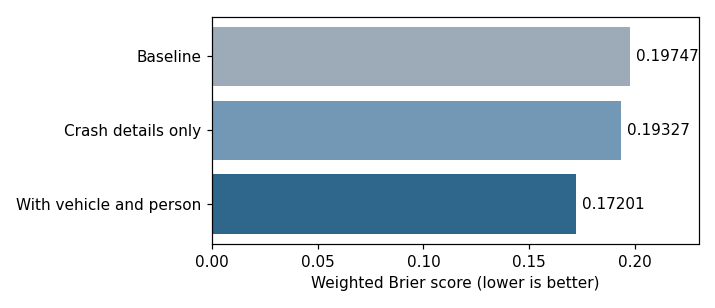

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score

names = ["Baseline", "Crash details only", "With vehicle and person"]
scores = [weighted_brier(y, predictions, weights)
          for predictions in [baseline, context, combined]]

for name, score in zip(names, scores):
    print(f"{name}: {score:.5f}")

same_c_context = weighted_brier(y, context_same_c, weights)
print(f"Same C = 1: {same_c_context:.5f} with crash details only vs {scores[2]:.5f} with added details")

recall = recall_score(y, combined >= 0.5, sample_weight=weights)
print(f"Combined model recall at 0.50: {recall:.1%}")

fig, ax = plt.subplots(figsize=(6.5, 2.8))
bars = ax.barh(names, scores, color=["#9daab7", "#7298b6", "#2e668c"])
ax.bar_label(bars, fmt="%.5f", padding=4)
ax.set(xlim=(0, 0.23), xlabel="Weighted Brier score (lower is better)")
ax.invert_yaxis()
fig.tight_layout()

plt.show()


### What we found

Using just the crash details did a little better than the baseline. Adding vehicle and person information helped more: the weighted Brier score dropped from **0.19327** to **0.17201**. A lower Brier score means the predicted probabilities were closer to what actually happened.

The same check at `C = 1` yielded **0.19335** with crash details only and **0.17201** with the added details. So the improvement wasn't just from choosing a different `C`.

At a 50% cutoff, the combined model caught about **16%** of injury crashes after weighting. Its probabilities were better overall, but it still missed most injury crashes at that cutoff. We only checked this on the development data. We haven't run the final test.

If the team rebuilds the data or changes the development split, use the new data and its matching fold file together.
